# 03 - Clustering hiérarchique et par densité

Objectif : CAH et DBSCAN (chapitres 3.2 et 3.3).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import gower
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_moons

import sys
sys.path.insert(0, "..")
import fonctions

X, y, Xa, Xb = fonctions.preparer()
G = gower.gower_matrix(Xb)

## 1. CAH

1. Au départ, chaque client est un groupe.
2. On fusionne les deux groupes les plus proches.
3. On recommence jusqu'à avoir un seul groupe.

Distance entre deux groupes (le lien) :

- single : $\min d(x,y)$
- complete : $\max d(x,y)$
- average : moyenne des $d(x,y)$
- Ward : $\dfrac{|C_i||C_j|}{|C_i| + |C_j|}\lVert \mu_i - \mu_j \rVert^2$ (hausse de l'inertie)

Ward utilise la distance euclidienne sur (a), les autres utilisent Gower.

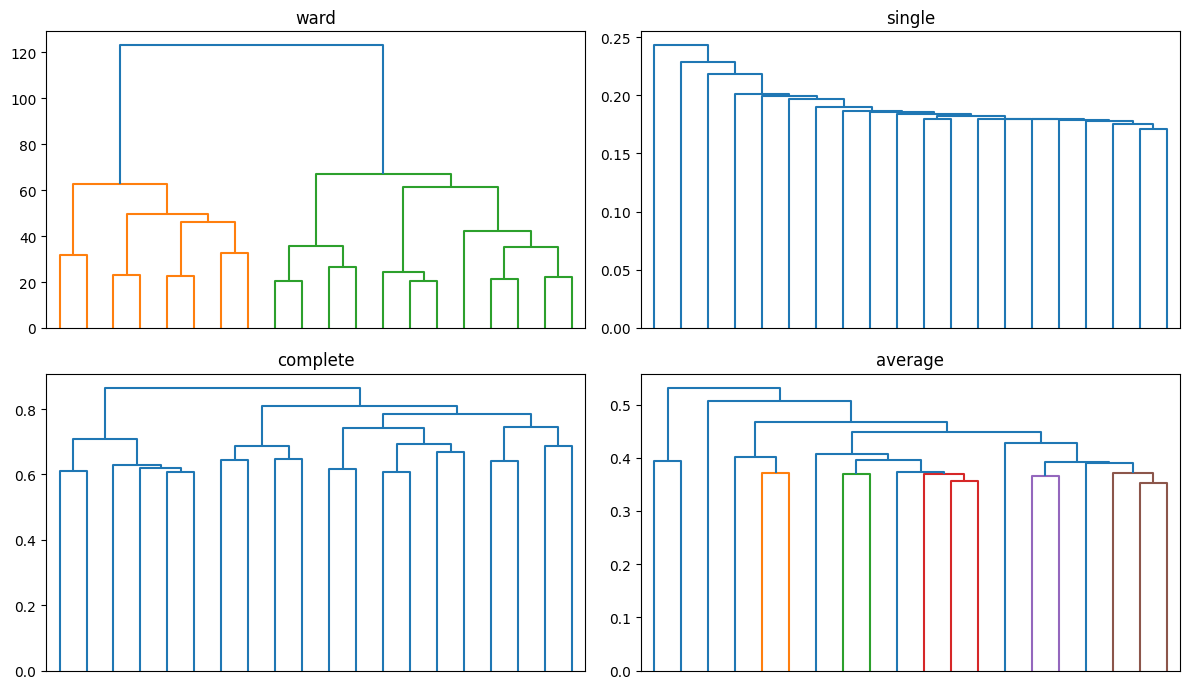

In [2]:
G_vecteur = squareform(G, checks=False)   # format demandé par scipy

liens = {}
liens["ward"] = linkage(Xa, method="ward")
liens["single"] = linkage(G_vecteur, method="single")
liens["complete"] = linkage(G_vecteur, method="complete")
liens["average"] = linkage(G_vecteur, method="average")

noms = ["ward", "single", "complete", "average"]
plt.figure(figsize=(12, 7))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    dendrogram(liens[noms[i]], truncate_mode="lastp", p=20, no_labels=True)
    plt.title(noms[i])
plt.tight_layout()
plt.show()

In [3]:
# taille des groupes quand on coupe en 3
for nom in noms:
    groupes = fcluster(liens[nom], t=3, criterion="maxclust")
    print(nom, ":", np.bincount(groupes)[1:])

ward : [2617  257 1126]
single : [3998    1    1]
complete : [1561  384 2055]
average : [   7    2 3991]


single et average donnent un groupe géant et des groupes de 1 ou 2 clients : c'est l'effet de chaînage.

## 2. Où couper le dendrogramme de Ward ?

On regarde la hauteur des dernières fusions. Un grand saut = on fusionne deux groupes très différents.

de 2 groupes à 1 : saut de 56.0
de 3 groupes à 2 : saut de 4.1
de 4 groupes à 3 : saut de 1.5
de 5 groupes à 4 : saut de 11.6
de 6 groupes à 5 : saut de 3.5
de 7 groupes à 6 : saut de 4.0
de 8 groupes à 7 : saut de 6.7
de 9 groupes à 8 : saut de 0.1
de 10 groupes à 9 : saut de 2.9


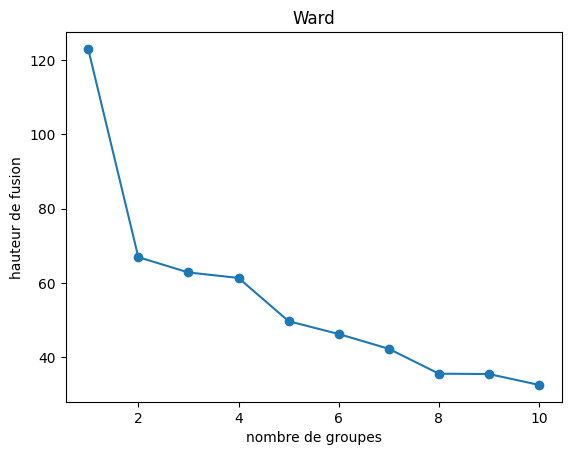

In [4]:
hauteurs = liens["ward"][-10:, 2]      # 10 dernières fusions
hauteurs = hauteurs[::-1]               # de 1 groupe à 10 groupes

for k in range(2, 11):
    saut = hauteurs[k - 2] - hauteurs[k - 1]
    print("de", k, "groupes à", k - 1, ": saut de", round(saut, 1))

plt.plot(range(1, 11), hauteurs, marker="o")
plt.xlabel("nombre de groupes")
plt.ylabel("hauteur de fusion")
plt.title("Ward")
plt.show()

Le plus grand saut est entre 2 et 1 groupe : le dendrogramme suggère k = 2. Le choix final est fait dans le notebook 04.

## 3. DBSCAN

- $d^*$ (eps) : le rayon
- $e^*$ (min_samples) : le nombre minimum de voisins
- un point est dense si $|\{Q : d(P,Q) \le d^*\}| \ge e^*$
- un point non dense proche d'un point dense est un point de bordure
- les autres points sont du bruit

On travaille sur la PCA en 2D, avec $e^* = 4$.

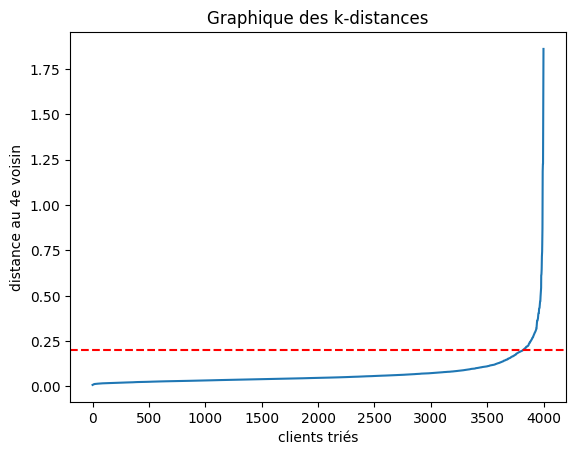

In [5]:
Z2 = PCA(n_components=2, random_state=42).fit_transform(Xa)

# distance de chaque client à son 4e voisin, triée
voisins = NearestNeighbors(n_neighbors=4).fit(Z2)
distances, indices = voisins.kneighbors(Z2)
k_distances = np.sort(distances[:, 3])

plt.plot(k_distances)
plt.axhline(0.2, color="red", linestyle="--")
plt.xlabel("clients triés")
plt.ylabel("distance au 4e voisin")
plt.title("Graphique des k-distances")
plt.show()

La courbe monte brusquement vers 0,2 (le coude) : on prend $d^* = 0{,}2$.

Nombre de groupes : 10
Points denses : 3817
Points de bordure : 52
Bruit : 131
Taille des groupes : [3801   10   25    4    6    4    9    4    2    4]


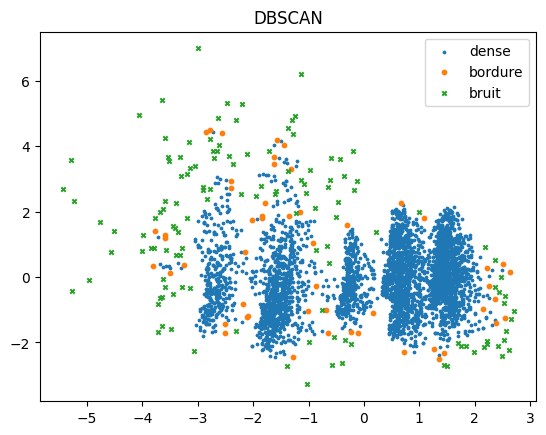

In [6]:
dbscan = DBSCAN(eps=0.2, min_samples=4)
groupes_db = dbscan.fit_predict(Z2)

dense = np.zeros(len(Z2), dtype=bool)
dense[dbscan.core_sample_indices_] = True
bruit = groupes_db == -1
bordure = (groupes_db >= 0) & (dense == False)

print("Nombre de groupes :", groupes_db.max() + 1)
print("Points denses :", dense.sum())
print("Points de bordure :", bordure.sum())
print("Bruit :", bruit.sum())
print("Taille des groupes :", np.bincount(groupes_db[groupes_db >= 0]))

plt.scatter(Z2[dense, 0], Z2[dense, 1], s=3, label="dense")
plt.scatter(Z2[bordure, 0], Z2[bordure, 1], s=10, label="bordure")
plt.scatter(Z2[bruit, 0], Z2[bruit, 1], s=10, marker="x", label="bruit")
plt.legend()
plt.title("DBSCAN")
plt.show()

DBSCAN trouve un grand groupe et quelques petits amas : il n'y a pas de zones denses séparées. Le bruit correspond aux clients atypiques.

## 4. Limites de K-means

K-means fait des groupes ronds autour des centres et met tous les points dans un groupe. Exemple avec deux croissants et 2 points isolés :

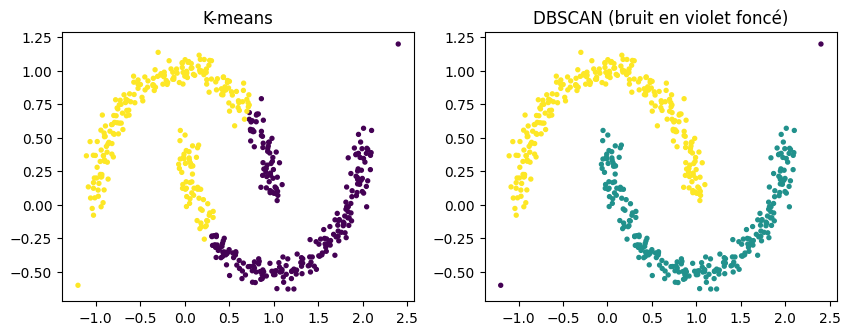

In [7]:
lunes, _ = make_moons(n_samples=500, noise=0.06, random_state=42)
lunes = np.vstack([lunes, [[2.4, 1.2], [-1.2, -0.6]]])   # 2 points isolés

groupes_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(lunes)
groupes_dbs = DBSCAN(eps=0.2, min_samples=5).fit_predict(lunes)

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.scatter(lunes[:, 0], lunes[:, 1], c=groupes_km, s=8)
plt.title("K-means")
plt.subplot(1, 2, 2)
plt.scatter(lunes[:, 0], lunes[:, 1], c=groupes_dbs, s=8)
plt.title("DBSCAN (bruit en violet foncé)")
plt.show()

K-means coupe les croissants. DBSCAN suit leur forme et met les points isolés à part.